# Problem 1

We saw a simple CNN notebook (1_pytorch_basic_cnn_digits.ipynb) where 
digits from Sklearn were used and a classification model was created. You will expand 
on that work and instead of sklearn dataset, use the MNIST dataset from torchvision 
where images are of size 28 x 28. Build model with torchvision Dataset. Next draw a few 
numbers in your own handwriting and see if the model can detect it, just inference. Do 
not over do this.

In [1]:
# 1. Setup and imports
import random
import numpy as np
import matplotlib.pyplot as plt

import torchvision
import torchvision.transforms.v2 as T

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Random processes are used when splitting and shuffling data and when
# initializing model weights. A fixed seed makes results more repeatable.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
from torch.utils.data import random_split

# Apple Silicon use MPS; laptops with NVIDIA GPUs can use CUDA.
# This tiny dataset also trains quickly on a CPU. So dont worry
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")

PyTorch version: 2.14.0+rocm7.14
Using device: cuda


Training images shape: torch.Size([1, 28, 28])
Testing images shape: torch.Size([1, 28, 28])
Number of training images: 60000
Number of testing images: 10000
(training) Class Names  ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Minimum pixel value: 0.0
Maximum pixel value: 1.0


/home/zoe/Github/deep_learning_course/.venv-1/lib/python3.12/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


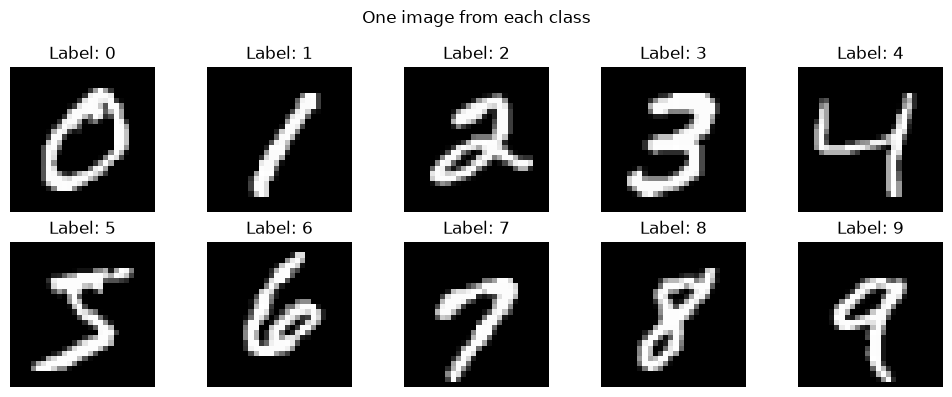

In [2]:
# 2. Load and explore the images

toTensor = T.ToTensor()
train_data = torchvision.datasets.MNIST(
    root="datasets", train=True, download=True, transform=toTensor)
test_data = torchvision.datasets.MNIST(
    root="datasets", train=False, download=True, transform=toTensor)

print(f"Training images shape: {train_data[0][0].shape}")
print(f"Testing images shape: {test_data[0][0].shape}")
print(f"Number of training images: {len(train_data)}")
print(f"Number of testing images: {len(test_data)}")


class_names = train_data.classes
print("(training) Class Names ", class_names)


print(f"Minimum pixel value: {train_data[0][0].min()}")
print(f"Maximum pixel value: {train_data[0][0].max()}")

images = train_data.data.numpy()
labels = train_data.targets.numpy()

# Display one example from each class.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    example_index = np.where(labels == digit)[0][0]
    ax.imshow(images[example_index], cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")
plt.suptitle("One image from each class")
plt.tight_layout()
plt.show()

## 3. Create training, validation, and test datasets

Note, I am using 10% for testing and 10% for validation. The test set is 20% of the full amount, so I am spliting it in 2. The training data is being left as is at 80%. 

This dataset comes prenormalized (values between 0 and 1) and the dataloader below outputs labels as type `torch.int64`, so no further preprocessing is necessary.

In [3]:
validating_data, testing_data = random_split(
    test_data,
    [5000, 5000]
)

## 4. Put the data into DataLoaders

We will use  `TensorDataset` that pairs every image with its label. And also `DataLoader` which serves small batches to the model. Training data is shuffled each epoch so the model does not learn from a fixed ordering. Validation and test data do not need shuffling.

`train_generator` creates a random-number generator with a fixed starting point. in our case it controls how the DataLoader shuffles the training images


In [ ]:
BATCH_SIZE = 64

train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator = train_generator
)

test_loader = DataLoader(
    testing_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    validating_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)


batch_images, batch_labels = next(iter(train_loader))
print(f"Image batch shape: {batch_images.shape}")
print(f"Label batch shape: {batch_labels.shape}")

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


## 5. Define a vanilla CNN

The network has two conceptual parts:

- **Feature extractor:** convolution layers slide small filters across the image. ReLU adds non-linearity, and max pooling reduces width and height.
- **Classifier:** the feature maps are flattened into a vector and passed to a linear layer that produces 10 class scores, called **logits**.

Shape changes: `(1, 8, 8) → (8, 8, 8) → (8, 4, 4) → (16, 4, 4) → (16, 2, 2) → 64 → 10`.

In [ ]:
class BasicCNN(nn.Module):
    """A small CNN for 8 x 8, one-channel images."""

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Padding=1 keeps height and width at 8 x 8.
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1),
            nn.ReLU(),
            # Pooling changes 8 x 8 into 4 x 4.
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            # Pooling changes 4 x 4 into 2 x 2.
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),                    # 16 feature maps x 2 x 2 = 64 values
            nn.Linear(16 * 2 * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 10),              # One score for each digit
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = BasicCNN().to(device)
print(model)

# Confirm that a batch produces one row of 10 scores per image.
with torch.no_grad():
    example_output = model(batch_images.to(device))
print(f"Model output shape: {example_output.shape}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

BasicCNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=10, bias=True)
  )
)


MIOpen(HIP): Warning [OpenRuntimeLibraryForDevice] CK grouped conv library not found for device gfx1030: libMIOpenCKGroupedConv_gfx1030.so: cannot open shared object file: No such file or directory


Model output shape: torch.Size([64, 10])
Trainable parameters: 3,658


## 6. Loss, optimizer, and evaluation function

`CrossEntropyLoss` compares the 10 raw class scores with the correct class. It already performs the softmax-related mathematics internally, so we **do not add a softmax layer** to the model.

The Adam optimizer updates weights to reduce loss. During evaluation, `model.eval()` turns off training-only behavior, and `torch.no_grad()` avoids storing gradients, saving memory.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

def evaluate(model, data_loader, criterion, device):
    """Return average loss and accuracy without changing model weights."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = model(inputs)
            loss = criterion(logits, targets)
            predictions = logits.argmax(dim=1)

            # Multiply by batch size because loss is an average for this batch.
            total_loss += loss.item() * inputs.size(0)
            total_correct += (predictions == targets).sum().item()
            total_examples += inputs.size(0)

    return total_loss / total_examples, total_correct / total_examples

## 7. Train the model

For each batch, training follows five steps: 
            clear old gradients, 
            make predictions, 
            calculate loss, 
            calculate gradients with backpropagation, 
            and update the weights. 

One complete pass through the training set is an **epoch**.

Logits are the raw scores the model produces for each possible class.
Logits are not probabilities: they can be negative and don’t need to sum to 1.

 Digit:  0    1     2    3    4    5    6    7    8    9
 Logits:
        [0.2, -1.0, 0.5, 3.1, 0.0, 0.8, -0.4, 1.2, 0.3, 0.1]

The highest score is 3.1 at index 3, so the predicted digit is 3.

During training, pass these raw scores directly to CrossEntropyLoss, PyTorch’s nn.CrossEntropyLoss already includes the probability-conversion calculation, so you give it the raw logits.

Conceptually, it does two things:
1. Converts logits into probabilities using softmax.
2. Calculates the loss from the probability assigned to the correct class

If you apply softmax first, CrossEntropyLoss treats those probabilities as raw scores and normalizes them again, changing the intended calculation.

In [ ]:
EPOCHS = 30
history = {
    "train_loss": [], "train_accuracy": [],
    "val_loss": [], "val_accuracy": [],
}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_examples = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()          # 1. Clear gradients from the previous batch.
        logits = model(inputs)         # 2. Forward pass: compute class scores.
        loss = criterion(logits, targets)  # 3. Measure prediction error.
        loss.backward()                # 4. Backward pass: compute gradients.
        optimizer.step()               # 5. Update the model's weights.

        predictions = logits.argmax(dim=1)
        running_loss += loss.item() * inputs.size(0)
        running_correct += (predictions == targets).sum().item()
        running_examples += inputs.size(0)

    train_loss = running_loss / running_examples
    train_accuracy = running_correct / running_examples
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.3f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.3f}"
    )

Epoch 01/30 | train loss 2.2845, accuracy 0.111 | val loss 2.2262, accuracy 0.248
Epoch 02/30 | train loss 2.0541, accuracy 0.430 | val loss 1.7402, accuracy 0.581
Epoch 03/30 | train loss 1.3566, accuracy 0.648 | val loss 1.0158, accuracy 0.722
Epoch 04/30 | train loss 0.7908, accuracy 0.776 | val loss 0.7208, accuracy 0.785
Epoch 05/30 | train loss 0.5216, accuracy 0.850 | val loss 0.5334, accuracy 0.848
Epoch 06/30 | train loss 0.4140, accuracy 0.861 | val loss 0.4313, accuracy 0.874
Epoch 07/30 | train loss 0.3348, accuracy 0.898 | val loss 0.3274, accuracy 0.885
Epoch 08/30 | train loss 0.2696, accuracy 0.919 | val loss 0.2863, accuracy 0.900
Epoch 09/30 | train loss 0.2326, accuracy 0.924 | val loss 0.2494, accuracy 0.926
Epoch 10/30 | train loss 0.2060, accuracy 0.939 | val loss 0.2239, accuracy 0.933
Epoch 11/30 | train loss 0.1782, accuracy 0.943 | val loss 0.2111, accuracy 0.933
Epoch 12/30 | train loss 0.1656, accuracy 0.947 | val loss 0.2199, accuracy 0.922
Epoch 13/30 | tr

## 8. Plot the learning curves

Loss measures error (lower is better), while accuracy is the fraction predicted correctly (higher is better). If training keeps improving while validation gets worse, the model may be overfitting.

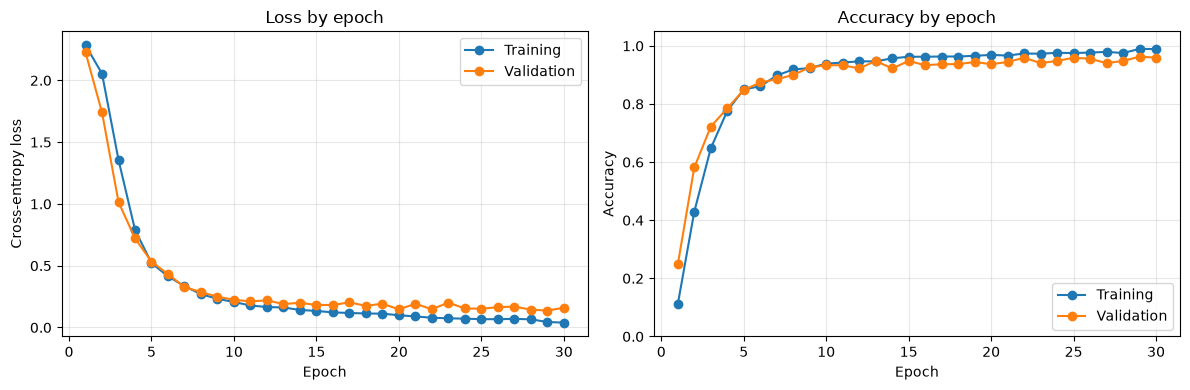

In [ ]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Final evaluation on the untouched test set

We use the test set only after training is finished. Besides overall loss and accuracy, the classification report shows precision, recall, and F1-score for every digit. The confusion matrix shows which digits are confused with one another.

Test loss:     0.1044
Test accuracy: 97.04%
Accuracy check with scikit-learn: 97.04%

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       1.00      0.79      0.88        28
           2       0.96      1.00      0.98        26
           3       0.97      1.00      0.98        28
           4       1.00      1.00      1.00        27
           5       1.00      1.00      1.00        27
           6       1.00      0.96      0.98        27
           7       1.00      1.00      1.00        27
           8       0.81      0.96      0.88        26
           9       1.00      1.00      1.00        27

    accuracy                           0.97       270
   macro avg       0.97      0.97      0.97       270
weighted avg       0.97      0.97      0.97       270



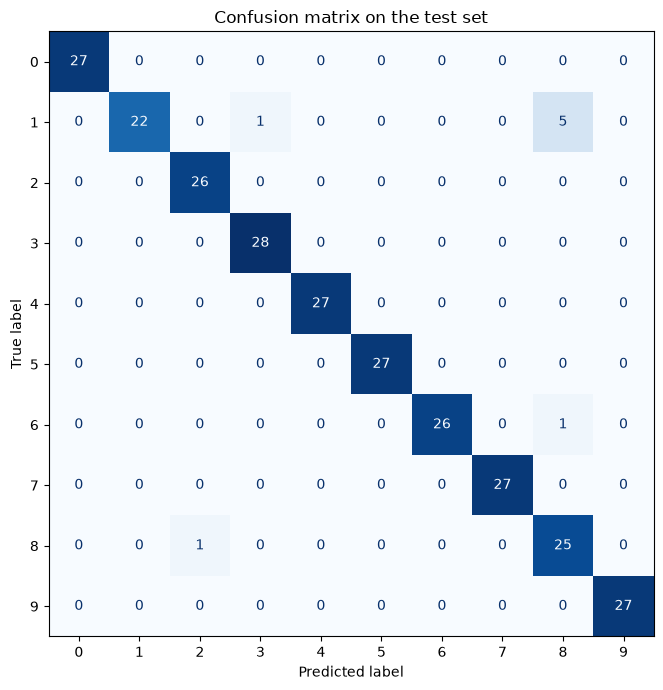

In [ ]:
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

# Collect every test prediction on the CPU for scikit-learn metrics.
model.eval()
all_predictions = []
all_targets = []
with torch.no_grad():
    for inputs, targets in test_loader:
        logits = model(inputs.to(device))
        predictions = logits.argmax(dim=1).cpu()
        all_predictions.extend(predictions.numpy())
        all_targets.extend(targets.numpy())

print(f"Accuracy check with scikit-learn: {accuracy_score(all_targets, all_predictions):.2%}")
print("\nClassification report:")
print(classification_report(all_targets, all_predictions, target_names=[str(x) for x in class_names]))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    all_targets, all_predictions, display_labels=class_names, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Confusion matrix on the test set")
plt.tight_layout()
plt.show()

### How to read the metrics

- **Accuracy:** proportion of all predictions that were correct.
- **Precision for a digit:** when the model predicts this digit, how often is it correct?
- **Recall for a digit:** of all real examples of this digit, how many did the model find?
- **F1-score:** a combined measure of precision and recall.
- **Support:** number of test examples belonging to that digit.
- **Confusion matrix:** correct predictions are on the main diagonal; off-diagonal cells are mistakes.

## 10. Look at individual predictions

A metric summarizes performance, but seeing individual examples makes the result more concrete. Green titles are correct predictions and red titles are mistakes.

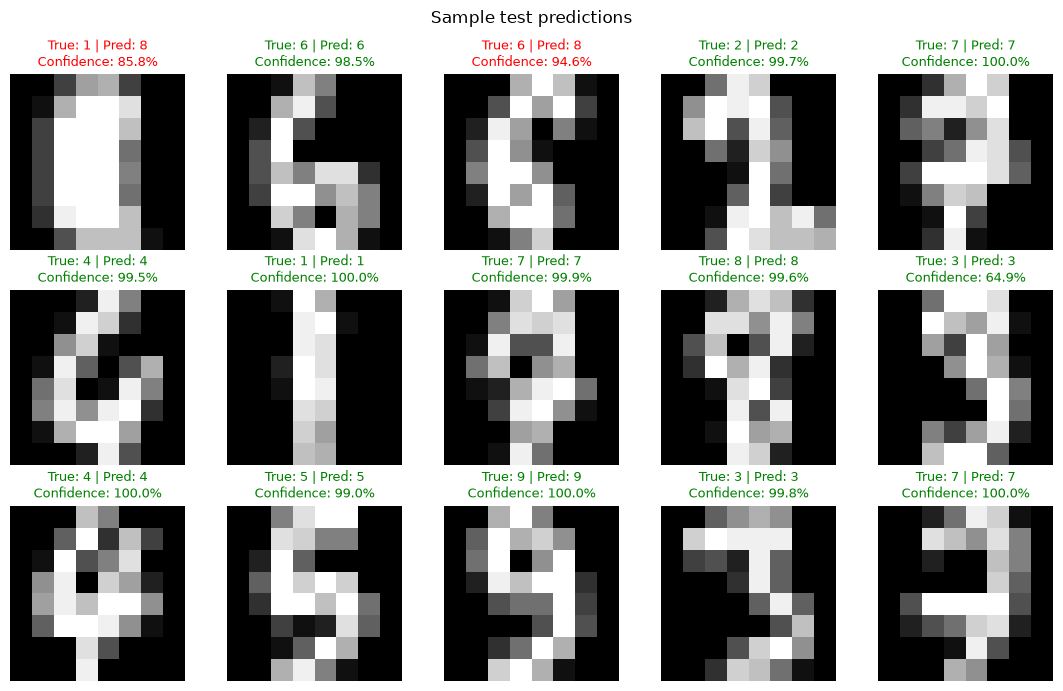

In [ ]:
# Use a fixed random generator so the displayed sample is repeatable.
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_test_t), size=15, replace=False)

model.eval()
with torch.no_grad():
    sample_logits = model(X_test_t[sample_indices].to(device))
    sample_probabilities = torch.softmax(sample_logits, dim=1).cpu()
    sample_predictions = sample_probabilities.argmax(dim=1)

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, index, prediction, probabilities in zip(
    axes.flat, sample_indices, sample_predictions, sample_probabilities
):
    actual = int(y_test_t[index])
    predicted = int(prediction)
    confidence = float(probabilities[predicted])
    color = "green" if predicted == actual else "red"

    ax.imshow(X_test_t[index, 0], cmap="gray")
    ax.set_title(
        f"True: {actual} | Pred: {predicted}\nConfidence: {confidence:.1%}",
        color=color, fontsize=9
    )
    ax.axis("off")

plt.suptitle("Sample test predictions")
plt.tight_layout()
plt.show()

## 11. Save and reload the trained model (optional)

Saving a `state_dict` stores the learned weights. To use them later, create the same architecture and load the weights into it.

In [ ]:
MODEL_PATH = "basic_cnn_digits.pth"
torch.save(model.state_dict(), MODEL_PATH)
print(f"Saved weights to {MODEL_PATH}")

# Example reload:
reloaded_model = BasicCNN().to(device)
reloaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
reloaded_model.eval()
reloaded_loss, reloaded_accuracy = evaluate(reloaded_model, test_loader, criterion, device)
print(f"Reloaded model test accuracy: {reloaded_accuracy:.2%}")

Saved weights to basic_cnn_digits.pth
Reloaded model test accuracy: 97.04%


## Summary

Through this example we have used a CNN and seen a full image-classification workflow: data loading, splitting, preprocessing, batching, CNN construction, training, validation, final testing, metrics, visualization, and saving weights. 